# 2 · A Tuna-17 noise model fitted to our own hardware data

Quantum Inspire publishes Tuna-17's connectivity and gate set (`tfd_study/tuna17.json`) but **no error rates**: its qiskit target carries none, and the metadata API returns *Not Found* for Tuna-17. So the noise model is fitted to what our own Tuna-17 runs measured instead.

**Data.** `results/parallel_20261019_175824`: 2+2 TFD circuits on Tuna-17 qubits 2-4-5-8, with readout-corrected 36-setting tomography of both subsystems, for the reference angles and every SPSA replica. That is 34 reconstructed states with known angles.

**Model** (`tfd_study/devices.py`, uniform over qubits):
- every CZ: depolarizing error p_cz, then amplitude damping γ on both qubits (T₁-like decay towards |0⟩);
- every rx/ry: depolarizing error p_1q = 0.05 · p_cz (rz is virtual and error-free);
- readout: P(1|0) and P(0|1) taken directly from the run's 16-state calibration matrix.

**Fit** (`python -m tfd_study.fit_noise`). For each recorded state, simulate the circuit that ran: same `TFDCircuit`, same qubits, compiled to Tuna's native gates. Then choose (p_cz, γ) to match the measured fidelity-to-Gibbs and purity of ρ_A and ρ_B. Both quantities are independent of qubit-ordering conventions. The measured states were readout-corrected, so readout does not enter this fit.

In [1]:
import os
for v in ("OPENBLAS_NUM_THREADS", "OMP_NUM_THREADS", "MKL_NUM_THREADS"):
    os.environ.setdefault(v, "1")          # before numpy: see tfd_study/__init__.py
import json, sys, warnings
from pathlib import Path
import numpy as np, pandas as pd, matplotlib.pyplot as plt
from matplotlib.lines import Line2D

ROOT = next(p for p in (Path.cwd(), *Path.cwd().parents) if (p / "tfd_study").is_dir())
sys.path.insert(0, str(ROOT))
warnings.filterwarnings("ignore")
from tfd_study import model, devices
from tfd_study.plotting import *
apply_style()
RES = ROOT / "tfd_study" / "results"
FIGS = ROOT / "tfd_study" / "figures"; FIGS.mkdir(exist_ok=True)
pd.set_option("display.precision", 4)

In [2]:
fit = json.loads((ROOT / "tfd_study" / "noise_fit.json").read_text(encoding="utf-8"))
pd.Series({"p_cz (depolarizing per CZ)": fit["p_cz"], "γ (amplitude damping per qubit per CZ)": fit["gamma_cz"],
           "p_1q (depolarizing per rx/ry)": fit["p_1q"], "readout P(1|0)": round(fit["readout"][0], 4),
           "readout P(0|1)": round(fit["readout"][1], 4), "rms mismatch (fidelity, purity)": fit["rms_fid_purity"],
           "rms, depolarizing-only model": fit["rms_depolarizing_only"]}, name="value").to_frame()

,value
p_cz (depolarizing per CZ),0.0230
γ (amplitude damping per qubit per CZ),0.0270
p_1q (depolarizing per rx/ry),0.0011
readout P(1|0),0.0374
readout P(0|1),0.0306
"rms mismatch (fidelity, purity)",0.0419
"rms, depolarizing-only model",0.0426


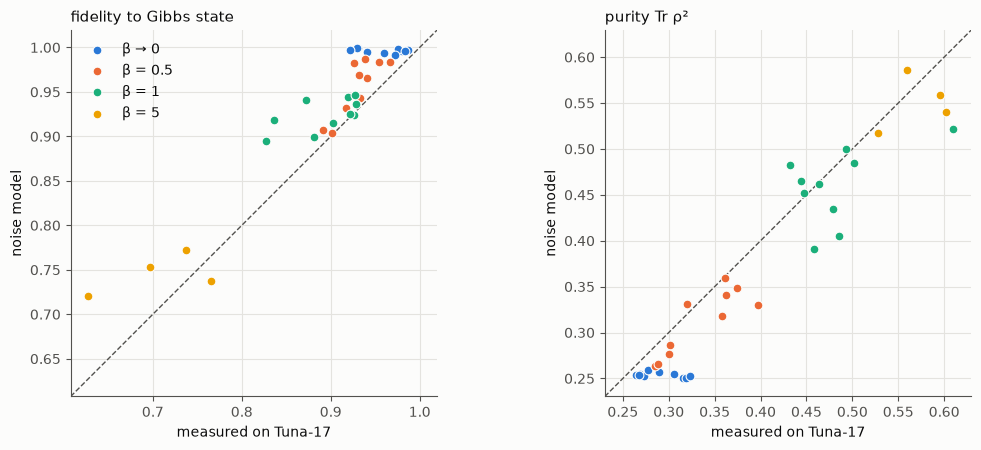

In [3]:
ps = pd.DataFrame(fit["per_state"])
betas = sorted(ps.beta.unique())
colors = {b: SLOTS[i] for i, b in enumerate(betas)}
fig, axes = plt.subplots(1, 2, figsize=(11, 4.6))
for ax, (m, s, title) in zip(axes, (("measured_fid", "model_fid", "fidelity to Gibbs state"),
                                    ("measured_purity", "model_purity", "purity Tr ρ²"))):
    lo, hi = min(ps[m].min(), ps[s].min()) - 0.02, max(ps[m].max(), ps[s].max()) + 0.02
    ax.plot([lo, hi], [lo, hi], color=INK_DIM, lw=1, ls="--", zorder=1)
    for b in betas:
        sub = ps[ps.beta == b]
        ax.scatter(sub[m], sub[s], color=colors[b], s=40, edgecolor=SURFACE, lw=0.8, zorder=2, label=beta_label(b))
    ax.set_xlim(lo, hi); ax.set_ylim(lo, hi); ax.set_aspect("equal")
    ax.set_xlabel(f"measured on Tuna-17"); ax.set_ylabel("noise model"); ax.set_title(title)
axes[0].legend(loc="upper left")
fig.tight_layout(); fig.savefig(FIGS / "noise_model_fit.png", dpi=130, bbox_inches="tight"); plt.show()

**Reading the fit.**
- From β = 0.5 up, the model tracks the hardware within a few percent in both fidelity and purity.
- **At β → 0 the hardware states are purer and lower in fidelity than any gate-noise model gives.** The ideal state there is maximally mixed (purity 0.25), and depolarizing noise can only keep it there. The measured 0.26–0.32 points to residual state-preparation and measurement error that the readout correction does not remove. The model is therefore slightly optimistic at β → 0.
- Depolarizing-only (p_cz ≈ 4.6 %) fits almost as well as depolarizing + damping. The two differ for deeper circuits, so the study in notebook 3 checks every conclusion against both, and against gate noise scaled by ×0.5 and ×1.5.
- **Only qubits 2-4-5-8 were measured.** The 3+3 and 4+4 ladders use other qubits, which this model assumes behave the same. A short characterization run on the exact qubits of the final layout is the cheapest way to confirm that (see notebook 4).

## What the noise costs, by size and depth

Take the best angles the circuit allows (exact free energy, no noise) at each hardware β and run them through the noise model. This is the most a perfect optimizer could show on this device, before any SPSA error. Shaded band: gate noise ×0.5 to ×1.5. Dotted: the depolarizing-only model.

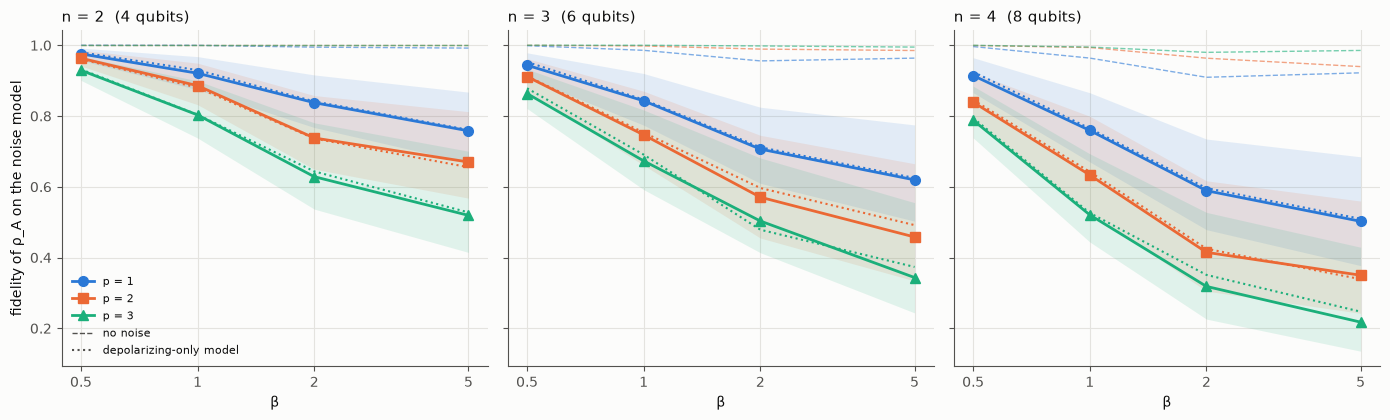

In [4]:
ce = json.loads((RES / "ceilings.json").read_text(encoding="utf-8"))
crows = []
for r in ce["results"]:
    for row in r["rows"]:
        crows.append({"n": r["n"], "p": r["p"], "s": r["s"], **{k: v for k, v in row.items() if k != "theta"}})
cdf = pd.DataFrame(crows)
ex = cdf[cdf.target == "exact F"]

fig, axes = plt.subplots(1, 3, figsize=(14, 4.3), sharey=True)
for ax, n in zip(axes, (2, 3, 4)):
    for p in (1, 2, 3):
        c = ex[(ex.n == n) & (ex.p == p)].sort_values("beta")
        col = LAYER_COLORS[p]
        ax.fill_between(c.beta, c["fid_x1.5"], c["fid_x0.5"], color=col, alpha=0.12, lw=0)
        ax.plot(c.beta, c.fid_fit, color=col, marker=LAYER_MARKERS[p], label=f"p = {p}")
        ax.plot(c.beta, c["fid_depolarizing-only"], color=col, ls=":", lw=1.5)
        ax.plot(c.beta, c.fid_noiseless, color=col, ls="--", lw=1, alpha=0.6)
    ax.set_xscale("log"); ax.set_xticks(ce["betas"], [f"{b:g}" for b in ce["betas"]]); ax.xaxis.set_minor_locator(plt.NullLocator())
    ax.set_xlabel("β"); ax.set_title(f"n = {n}  ({2 * n} qubits)")
axes[0].set_ylabel("fidelity of ρ_A on the noise model")
axes[0].legend(handles=[Line2D([], [], color=LAYER_COLORS[p], marker=LAYER_MARKERS[p], label=f"p = {p}") for p in (1, 2, 3)]
               + [Line2D([], [], color=INK_DIM, ls="--", lw=1, label="no noise"),
                  Line2D([], [], color=INK_DIM, ls=":", lw=1.5, label="depolarizing-only model")], loc="lower left", fontsize=8)
fig.tight_layout(); fig.savefig(FIGS / "noisy_ceiling.png", dpi=130, bbox_inches="tight"); plt.show()

In [5]:
tab = (ex.groupby(["n", "p"])[["fid_noiseless", "fid_fit", "fid_x0.5", "fid_x1.5", "fid_depolarizing-only"]]
         .mean().round(3))
tab.columns = ["no noise", "fitted model", "noise ×0.5", "noise ×1.5", "depolarizing-only"]
tab.insert(0, "CZ", [devices.cz_count(devices.to_device(model.bound_ansatz(n, p, np.full(4 * p, .3)), devices.default_layout(n)))
                     for n, p in tab.index])
print("Mean fidelity over β ∈ {0.5, 1, 2, 5}, best angles (exact free energy):")
tab

Mean fidelity over β ∈ {0.5, 1, 2, 5}, best angles (exact free energy):


CZ  no noise  fitted model  noise ×0.5  noise ×1.5  depolarizing-only
n p                                                                       
2 1  10     0.997         0.873       0.936       0.817              0.878
  2  18     1.000         0.814       0.901       0.748              0.808
  3  26     1.000         0.720       0.837       0.647              0.727
3 1  17     0.976         0.778       0.875       0.699              0.784
  2  31     0.993         0.672       0.811       0.580              0.689
  3  45     0.998         0.596       0.746       0.518              0.605
4 1  24     0.948         0.691       0.813       0.598              0.699
  2  44     0.974         0.559       0.725       0.465              0.563
  3  64     0.990         0.461       0.634       0.386              0.480

## Conclusions (noise)

1. **The model reproduces our Tuna-17 data to about 0.04** in fidelity and purity. It is slightly optimistic at β → 0, where residual readout and state-preparation error dominates.
2. **On this device, every extra layer costs more than it gains.**
   - Mean best-case fidelity over β, from p = 1 to 2 to 3: **0.873 → 0.814 → 0.720** for 2+2, **0.778 → 0.672 → 0.596** for 3+3 and **0.691 → 0.559 → 0.461** for 4+4.
   - Without noise, an extra layer gains at most 0.02–0.04. Each one costs 6n − 4 CZ at about 2–5 % error per CZ, so the noise wipes that gain out several times over.
3. **The ranking is robust.** p = 1 stays best with half the fitted gate noise, with 1.5× the noise and with the depolarizing-only model. Only a device several times better than the fit would make p = 2 worthwhile.
4. **Low temperature is where noise hurts.** At β = 5, the best case is 0.76 (2+2), 0.62 (3+3) and 0.50 (4+4) with one layer. At β = 0.5 all sizes are above 0.91. The β grid of a hardware run should keep its emphasis on β ≤ 2.
5. **These numbers are ceilings for a perfect optimizer.** Notebook 3 asks how close SPSA gets with a hardware-sized budget.